# 🧪 Autoencoders — Lab (Notebook 1 of 2)
**Edulateral · Module 4 · Google Colab or Kaggle (GPU optional, CPU works)**


**How every step works**
1. **Read** the explanation above the cell (it walks through the code line by line).
2. **Predict**: call `predict("key", "your guess")` *before* running the experiment. The experiment refuses to run without it, and your prediction is timestamped.
3. **Run** the cell and **record** what you saw with `record("key", value)`.
4. At the end, one cell exports `journal_<roll>.json`. Upload it as your submission.

> Colab: `Runtime → Change runtime type → T4 GPU` makes it faster, but everything also runs on CPU in a few minutes.

In [1]:
ROLL_NO = "01"          # <-- e.g. "21CS045"

import hashlib, json, time, math, random
assert ROLL_NO != "REPLACE_ME", "Type your roll number first!"
ROLL = ROLL_NO.strip().upper()
h = int(hashlib.sha256(ROLL.encode()).hexdigest(), 16)

SEED   = h % 100000
LATENT = [3, 4, 5, 6][(h >> 4) & 3]
NOISE  = [0.35, 0.45, 0.55, 0.65][(h >> 8) & 3]
UNSEEN = (h >> 12) % 10
PAIR   = ((h >> 16) % 10, (h >> 20) % 10)
if PAIR[0] == PAIR[1]: PAIR = (PAIR[0], (PAIR[0] + 3) % 10)

JOURNAL = {"roll": ROLL, "settings": dict(SEED=SEED, LATENT=LATENT, NOISE=NOISE, UNSEEN=UNSEEN, PAIR=PAIR),
           "predictions": {}, "records": {}}

def predict(key, text):
    "Lock a prediction BEFORE running the experiment."
    if key in JOURNAL["predictions"]:
        print("⚠️ already locked:", JOURNAL["predictions"][key]); return
    JOURNAL["predictions"][key] = {"text": str(text), "t": time.strftime("%H:%M:%S")}
    print(f"🔒 prediction '{key}' locked at {JOURNAL['predictions'][key]['t']}")

def need(key):
    if key not in JOURNAL["predictions"]:
        raise RuntimeError(f"Make your prediction first:  predict('{key}', '...')")

def record(key, value):
    JOURNAL["records"][key] = value
    print(f"📝 {key} = {value}")

print(f"Roll {ROLL}:  LATENT={LATENT}  NOISE={NOISE}  UNSEEN digit={UNSEEN}  PAIR={PAIR}  SEED={SEED}")

Roll 01:  LATENT=6  NOISE=0.65  UNSEEN digit=2  PAIR=(2, 5)  SEED=57812


## 1 · Load the data (MNIST, 70,000 handwritten digits)
**What the code does**
- `torchvision.datasets.MNIST(...)` downloads the dataset once (about 11 MB).
- `.data` is a `uint8` tensor of shape **(60000, 28, 28)** with values 0–255. Dividing by 255 maps it to **[0, 1]**. That matters because the decoder ends in a `Sigmoid`, which can only output values in [0, 1].
- We keep the whole dataset on the GPU as one tensor instead of using a `DataLoader`. MNIST is small, so this is about 10× faster.

100%|██████████| 9.91M/9.91M [00:00<00:00, 35.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.02MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 8.35MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.43MB/s]


train (60000, 1, 28, 28) test (10000, 1, 28, 28) device cpu


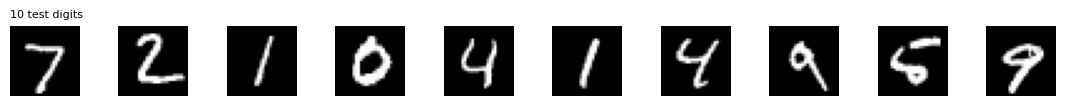

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, numpy as np, matplotlib.pyplot as plt

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"

tr = torchvision.datasets.MNIST("data", train=True,  download=True)
te = torchvision.datasets.MNIST("data", train=False, download=True)
Xtr = (tr.data.float() / 255.).unsqueeze(1).to(DEV);  Ytr = tr.targets.to(DEV)
Xte = (te.data.float() / 255.).unsqueeze(1).to(DEV);  Yte = te.targets.to(DEV)
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape), "device", DEV)

def show(rows, titles=None, n=10, size=1.1):
    "rows = list of (N,1,28,28) tensors -> one image grid, one row per tensor"
    fig, ax = plt.subplots(len(rows), n, figsize=(n*size, len(rows)*size))
    ax = np.atleast_2d(ax)
    for r, t in enumerate(rows):
        for c in range(n):
            ax[r, c].imshow(t[c, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1); ax[r, c].axis("off")
        if titles: ax[r, 0].set_title(titles[r], fontsize=8, loc="left")
    plt.tight_layout(); plt.show()

show([Xte[:10]], ["10 test digits"])

## 2 · The model, layer by layer
```
x (1×28×28) ─Flatten→ 784 ─Linear→ 256 ─ReLU→ 64 ─ReLU→ z (LATENT)      ← ENCODER  f(x)
z (LATENT) ─Linear→ 64 ─ReLU→ 256 ─ReLU→ 784 ─Sigmoid→ x̂ (1×28×28)       ← DECODER  g(z)
```
| Line | Meaning |
|---|---|
| `nn.Flatten()` | turns the 28×28 image into a vector of 784 numbers |
| `nn.Linear(784,256)` | `h = W·x + b`, with W of shape 256×784: 200,704 weights plus 256 biases |
| `nn.ReLU()` | `max(0,h)`: without it, stacked linear layers collapse into a single linear map (equivalent to PCA) |
| last encoder layer has **no** activation | the code `z` may be any real number |
| `nn.Sigmoid()` at the end | squeezes each pixel into (0,1), matching our [0,1] images |

**Loss:** mean squared error  $\;L = \frac{1}{784}\sum_i (x_i - \hat x_i)^2$. The network has to squeeze 784 numbers through `LATENT` numbers and rebuild them.

The **x-ray** cell below pushes one batch through the network and prints the shape after every layer.

In [3]:
class AE(nn.Module):
    def __init__(self, z=LATENT):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                 nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, z))
        self.dec = nn.Sequential(nn.Linear(z, 64), nn.ReLU(), nn.Linear(64, 256), nn.ReLU(),
                                 nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, x):
        z = self.enc(x)
        return self.dec(z).view(-1, 1, 28, 28), z

# ---- x-ray: shape after every layer ----
m = AE().to(DEV); t = Xte[:32]
print(f"{'input':<28}{tuple(t.shape)}")
for part in (m.enc, m.dec):
    for layer in part:
        t = layer(t); print(f"{str(layer)[:26]:<28}{tuple(t.shape)}")
n_params = sum(p.numel() for p in m.parameters())
print(f"\nparameters: {n_params:,}   compression 784 -> {LATENT} = {784/LATENT:.0f}x")

input                       (32, 1, 28, 28)
Flatten(start_dim=1, end_d  (32, 784)
Linear(in_features=784, ou  (32, 256)
ReLU()                      (32, 256)
Linear(in_features=256, ou  (32, 64)
ReLU()                      (32, 64)
Linear(in_features=64, out  (32, 6)
Linear(in_features=6, out_  (32, 64)
ReLU()                      (32, 64)
Linear(in_features=64, out  (32, 256)
ReLU()                      (32, 256)
Linear(in_features=256, ou  (32, 784)
Sigmoid()                   (32, 784)

parameters: 436,374   compression 784 -> 6 = 131x


📝 **Record by hand** (compute it on paper first, then compare with the printout): how many parameters does `Linear(64, LATENT)` have? Formula: `in·out + out`.

In [ ]:
record("params_total", n_params)
record("params_last_encoder_layer_by_hand", None)   # <-- replace None with your hand calculation

## 3 · Training loop
```python
for epoch in range(epochs):
    perm = torch.randperm(N)                 # shuffle the order every epoch
    for i in range(0, N, bs):
        x = X[perm[i:i+bs]]                  # one mini-batch (bs images)
        x_in = corrupt(x)                    # = x for a plain AE, a noisy x for a denoising AE
        loss = loss_fn(model, x_in, x)       # compare the reconstruction against the CLEAN x
        opt.zero_grad()                      # clear the old gradients (PyTorch adds them up otherwise)
        loss.backward()                      # backprop: dL/dW for every weight
        opt.step()                           # Adam update: W ← W − lr·m̂/(√v̂+ε)
```
`loss_fn` is a parameter, so the same loop trains the AE, the denoising AE and the VAE.

In [5]:
def mse_loss(model, x_in, x):
    xh, _ = model(x_in)
    return F.mse_loss(xh, x)

def train(model, epochs=5, loss_fn=mse_loss, X=None, corrupt=None, lr=1e-3, bs=256, quiet=False):
    X = Xtr if X is None else X
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X), device=X.device); tot = 0
        for i in range(0, len(X), bs):
            x = X[perm[i:i+bs]]
            x_in = corrupt(x) if corrupt else x
            loss = loss_fn(model, x_in, x)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x)
        hist.append(tot / len(X))
        if not quiet: print(f"epoch {ep+1}/{epochs}  loss {hist[-1]:.5f}")
    return hist

@torch.no_grad()
def test_mse(model, X=None, corrupt=None):
    model.eval(); X = Xte if X is None else X
    xh, _ = model(corrupt(X) if corrupt else X)
    return F.mse_loss(xh, X).item()

## 4 · Experiment 1: train *your* autoencoder
Your bottleneck is `LATENT` numbers. Before running: **will an "8" still look like an 8 after passing through it?** Which digit do you expect to come back worst?

In [7]:
predict("exp1_worst_digit", "...")      # <-- your guess, e.g. "8, because ..."

🔒 prediction 'exp1_worst_digit' locked at 06:04:53


epoch 1/5  loss 0.06856
epoch 2/5  loss 0.03763
epoch 3/5  loss 0.03093
epoch 4/5  loss 0.02888
epoch 5/5  loss 0.02770


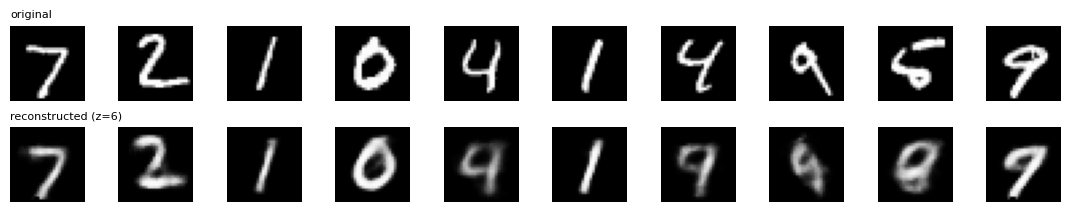

test MSE 0.0271
per-digit MSE {0: 0.0279, 1: 0.0073, 2: 0.0374, 3: 0.0309, 4: 0.0286, 5: 0.0365, 6: 0.0288, 7: 0.0198, 8: 0.0352, 9: 0.0225}
📝 exp1_test_mse = 0.0271
📝 exp1_per_digit = {0: 0.0279, 1: 0.0073, 2: 0.0374, 3: 0.0309, 4: 0.0286, 5: 0.0365, 6: 0.0288, 7: 0.0198, 8: 0.0352, 9: 0.0225}


In [8]:
need("exp1_worst_digit")
ae = AE(LATENT).to(DEV)
hist = train(ae, epochs=5)
mse = test_mse(ae)
xh, _ = ae.eval()(Xte[:10])
show([Xte[:10], xh], ["original", f"reconstructed (z={LATENT})"])

with torch.no_grad():   # per-digit error, to check your prediction
    per = ((ae(Xte)[0] - Xte) ** 2).mean((1, 2, 3))
    by_digit = {d: round(per[Yte == d].mean().item(), 4) for d in range(10)}
print("test MSE", round(mse, 5)); print("per-digit MSE", by_digit)
record("exp1_test_mse", round(mse, 5)); record("exp1_per_digit", by_digit)

📝 Was your prediction right? Explain in 1–2 lines **why** that digit is hardest (think about how many strokes and shapes it has).

In [ ]:
record("exp1_explain", "...")

## 5 · Experiment 2: how small can the bottleneck be?
We train four models with `z ∈ {2, LATENT, 16, 64}` for 3 epochs each and plot test MSE against z.
**Predict:** going from 16 → 64, does the error halve, barely change, or get worse?

In [9]:
predict("exp2_16_to_64", "...")

🔒 prediction 'exp2_16_to_64' locked at 06:09:28


z=2   test MSE 0.04896
z=6   test MSE 0.02867
z=16  test MSE 0.02441
z=64  test MSE 0.02313


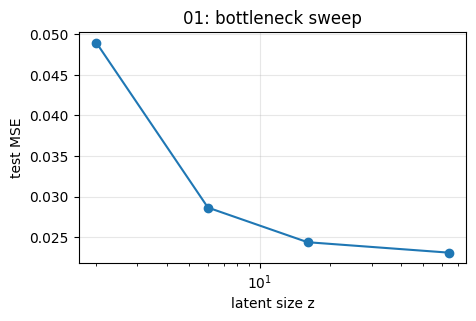

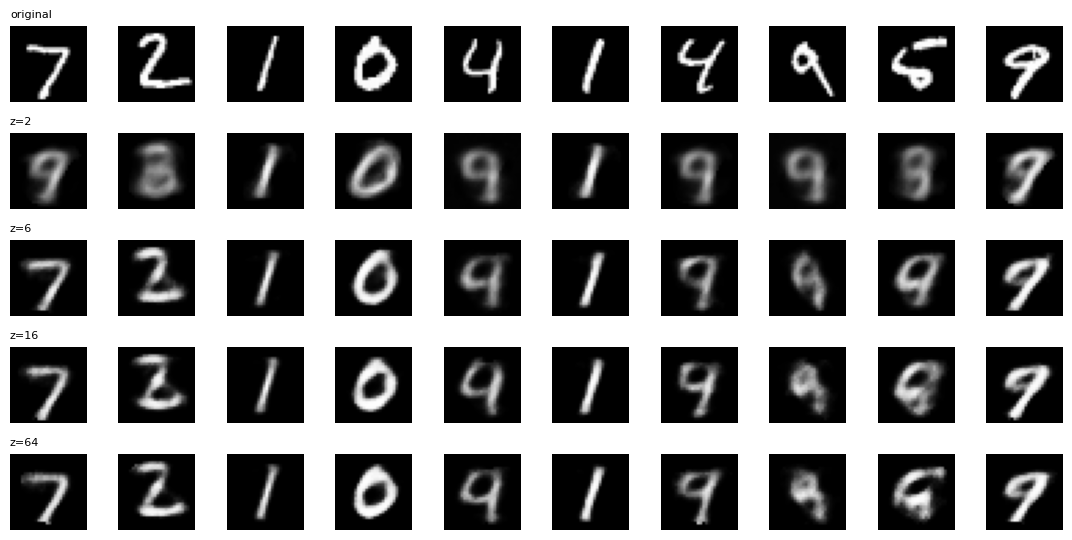

📝 exp2_sweep = {2: 0.04896, 6: 0.02867, 16: 0.02441, 64: 0.02313}


In [10]:
need("exp2_16_to_64")
sizes = sorted({2, LATENT, 16, 64}); sweep = {}; models = {}
for z in sizes:
    torch.manual_seed(SEED)
    models[z] = AE(z).to(DEV); train(models[z], epochs=3, quiet=True)
    sweep[z] = round(test_mse(models[z]), 5); print(f"z={z:<3} test MSE {sweep[z]}")
plt.figure(figsize=(5, 3)); plt.plot(list(sweep), list(sweep.values()), "o-"); plt.xscale("log")
plt.xlabel("latent size z"); plt.ylabel("test MSE"); plt.title(f"{ROLL}: bottleneck sweep"); plt.grid(alpha=.3); plt.show()
show([Xte[:10]] + [models[z].eval()(Xte[:10])[0] for z in sizes], ["original"] + [f"z={z}" for z in sizes])
record("exp2_sweep", sweep)

📝 Where is the *knee* of the curve? Why doesn't a bigger z keep helping much? (hint: how many numbers does it really take to describe *which digit* and *how it's written*?)

In [ ]:
record("exp2_explain", "...")

## 6 · Experiment 3: look inside the latent space
The z=2 model squeezes every digit into 2 numbers, so we can plot all 10,000 test digits as points. Colour = true label. **The autoencoder never saw a label**, so any grouping you see it found by itself.

In [ ]:
with torch.no_grad(): Z2 = models[2].enc(Xte).cpu().numpy()
plt.figure(figsize=(6, 5)); sc = plt.scatter(Z2[:, 0], Z2[:, 1], c=Yte.cpu(), cmap="tab10", s=2)
plt.colorbar(sc, ticks=range(10)); plt.title("2-D latent space (unsupervised)"); plt.show()

# walk across the latent plane and decode every point
g = 12; xs = np.linspace(*np.percentile(Z2[:, 0], [3, 97]), g); ys = np.linspace(*np.percentile(Z2[:, 1], [3, 97]), g)
grid = torch.tensor([[x, y] for y in ys[::-1] for x in xs], dtype=torch.float32, device=DEV)
with torch.no_grad(): imgs = models[2].dec(grid).view(g, g, 28, 28).cpu()
plt.figure(figsize=(6, 6)); plt.imshow(imgs.permute(0, 2, 1, 3).reshape(g*28, g*28), cmap="gray"); plt.axis("off")
plt.title("decoded latent grid"); plt.show()

📝 Name two digits whose clouds **overlap**, and one place in the decoded grid where you see a digit *morphing* into another.

In [ ]:
record("exp3_overlap", "..."); record("exp3_morph", "...")

## 7 · Experiment 4: denoising autoencoder (your noise level = `NOISE`)
The only change is **one argument**: `corrupt=add_noise`. The input is noisy, but the loss still compares against the *clean* image:
$$L = \lVert x - g(f(\tilde x))\rVert^2, \quad \tilde x = \text{clip}(x + \sigma\,\epsilon),\ \epsilon\sim\mathcal N(0,1)$$
PSNR (peak signal-to-noise ratio, higher is better) $= 10\log_{10}(1/\text{MSE})$ for images in [0, 1].

**Predict:** on noisy test images, how many dB better will the DAE be than your plain AE from Experiment 1?

In [ ]:
predict("exp4_gain_db", "...")

In [ ]:
need("exp4_gain_db")
def add_noise(x, s=NOISE): return (x + s * torch.randn_like(x)).clamp(0, 1)
psnr = lambda m: 10 * math.log10(1 / m)

torch.manual_seed(SEED); dae = AE(LATENT).to(DEV); train(dae, epochs=5, corrupt=add_noise)
torch.manual_seed(SEED + 1); noisy = add_noise(Xte)
with torch.no_grad():
    res = {"noisy input": F.mse_loss(noisy, Xte).item(),
           "plain AE": F.mse_loss(ae.eval()(noisy)[0], Xte).item(),
           "denoising AE": F.mse_loss(dae.eval()(noisy)[0], Xte).item()}
for k, v in res.items(): print(f"{k:<14} MSE {v:.4f}  PSNR {psnr(v):5.2f} dB")
show([Xte[:10], noisy[:10], ae(noisy[:10])[0], dae(noisy[:10])[0]],
     ["clean", f"noisy σ={NOISE}", "plain AE", "denoising AE"])
record("exp4_psnr", {k: round(psnr(v), 2) for k, v in res.items()})
torch.save(dae.state_dict(), f"dae_{ROLL}.pt")   # you will reuse this in Notebook 2 (Project 6)

📝 The plain AE never saw noise, yet it still removes some. Why? Then: what is the DAE's gain in dB, and how close was your prediction?

In [ ]:
record("exp4_explain", "...")

## 8 · Experiment 5: anomaly detection (the most common industry use)
We train an AE **only on digits that are not `UNSEEN`**. At test time, a high reconstruction error means "this doesn't look like anything I learned", and that error is the anomaly score.
ROC-AUC = the probability that a random anomaly gets a higher score than a random normal digit (0.5 = coin flip, 1.0 = perfect).

**Predict** your AUC (0.5–1.0):

In [ ]:
predict("exp5_auc", "...")

In [ ]:
need("exp5_auc")
from sklearn.metrics import roc_auc_score
torch.manual_seed(SEED); det = AE(LATENT).to(DEV)
train(det, epochs=5, X=Xtr[Ytr != UNSEEN])
with torch.no_grad(): score = ((det.eval()(Xte)[0] - Xte) ** 2).mean((1, 2, 3)).cpu().numpy()
is_anom = (Yte == UNSEEN).cpu().numpy()
auc = roc_auc_score(is_anom, score)
plt.figure(figsize=(6, 3))
plt.hist(score[~is_anom], 80, alpha=.6, density=True, label="seen digits")
plt.hist(score[is_anom], 80, alpha=.6, density=True, label=f"unseen digit {UNSEEN}")
plt.legend(); plt.xlabel("reconstruction error"); plt.title(f"AUC = {auc:.3f}"); plt.show()
top = np.argsort(-score)[:10]
show([Xte[top], det(Xte[top])[0]], ["10 highest scores", "what the AE rebuilt"])
print("labels of the top-10:", Yte[top].tolist())
record("exp5_auc", round(float(auc), 4)); record("exp5_top10_labels", Yte[top].tolist())

📝 Look at the top-10. Which of them are *not* your unseen digit, and why did they still score high? In fraud detection, what would those be called?

In [ ]:
record("exp5_explain", "...")

## 9 · Experiment 6: variational autoencoder (VAE)
Three changes turn an AE into a VAE:
1. The encoder outputs **two** vectors, `mu` and `logvar`, which describe a Gaussian for each image instead of a single point.
2. **Reparameterisation trick:** `z = mu + exp(0.5·logvar) · eps`, with `eps ~ N(0,1)`. The randomness sits in `eps`, so gradients can still flow into `mu` and `logvar`.
3. Loss = reconstruction + **β·KL**, where  $KL = -\tfrac12\sum(1 + \log\sigma^2 - \mu^2 - \sigma^2)$ pulls every code towards N(0, I). This is what lets you **sample new digits** from random noise.

| β | effect |
|---|---|
| small | sharp reconstructions, a messy latent space (bad samples) |
| large | a smooth latent space, blurry reconstructions |

**Predict:** with β = 4, will random samples look *sharper* or *blurrier* than with β = 0.25?

In [ ]:
predict("exp6_beta", "...")

In [ ]:
need("exp6_beta")
class VAE(nn.Module):
    def __init__(self, z=LATENT):
        super().__init__()
        self.body = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64), nn.ReLU())
        self.mu, self.logvar = nn.Linear(64, z), nn.Linear(64, z)
        self.dec = AE(z).dec
    def forward(self, x):
        h = self.body(x); mu, lv = self.mu(h), self.logvar(h)
        z = mu + torch.exp(0.5 * lv) * torch.randn_like(mu)        # reparameterisation trick
        self._kl = (-0.5 * (1 + lv - mu**2 - lv.exp()).sum(1)).mean()
        return self.dec(z).view(-1, 1, 28, 28), mu

def vae_loss(beta):
    def f(model, x_in, x):
        xh, _ = model(x_in)
        rec = F.binary_cross_entropy(xh, x, reduction="none").sum((1, 2, 3)).mean()
        return rec + beta * model._kl
    return f

vaes, rows, out = {}, [], {}
for beta in (0.25, 1.0, 4.0):
    torch.manual_seed(SEED); v = VAE(LATENT).to(DEV); train(v, epochs=5, loss_fn=vae_loss(beta), quiet=True)
    v.eval(); vaes[beta] = v
    with torch.no_grad():
        xh, _ = v(Xte); kl = v._kl.item()
        rows.append(v.dec(torch.randn(10, LATENT, device=DEV)).view(-1, 1, 28, 28))
    out[beta] = {"recon_mse": round(F.mse_loss(xh, Xte).item(), 4), "KL": round(kl, 2)}
    print(f"β={beta:<5} recon MSE {out[beta]['recon_mse']}  KL {out[beta]['KL']}")
show(rows, [f"random samples β={b}" for b in vaes])
record("exp6_beta_table", out)

### Morph between your two digits `PAIR`
Encode one example of each, then decode 10 evenly spaced points on the straight line between them (`(1-t)·mu_a + t·mu_b`).

In [ ]:
v = vaes[1.0]
a = Xte[(Yte == PAIR[0]).nonzero()[0]]; b = Xte[(Yte == PAIR[1]).nonzero()[0]]
with torch.no_grad():
    ma, mb = v(a)[1], v(b)[1]
    ts = torch.linspace(0, 1, 10, device=DEV).unsqueeze(1)
    path = v.dec((1 - ts) * ma + ts * mb).view(-1, 1, 28, 28)
    # same morph done in PIXEL space, for comparison
    pix = (1 - ts.view(-1, 1, 1, 1)) * a + ts.view(-1, 1, 1, 1) * b
show([pix, path], [f"pixel blend {PAIR[0]}→{PAIR[1]}", f"latent walk {PAIR[0]}→{PAIR[1]}"])

📝 Describe the difference between the pixel blend and the latent walk. At which step does the digit *change identity*?

In [ ]:
record("exp6_morph", "...")

## 10 · Export your journal
This saves `journal_<roll>.json` (with your settings, locked predictions, results and explanations) plus `dae_<roll>.pt`. Submit the JSON. Keep the `.pt` for Notebook 2.
The proof code at the end ties your numbers to your roll number. If you edit the JSON by hand, the code no longer matches.

In [ ]:
blob = json.dumps({k: JOURNAL[k] for k in ("roll", "settings", "records")}, sort_keys=True, default=str)
JOURNAL["proof"] = f"AEN1-{ROLL}-" + hashlib.sha256(blob.encode()).hexdigest()[:8].upper()
fn = f"journal_{ROLL}.json"
with open(fn, "w") as f: json.dump(JOURNAL, f, indent=2, default=str)
todo = [k for k, v in JOURNAL["records"].items() if v in (None, "...")]
print("saved", fn, "| proof", JOURNAL["proof"]); print("⚠️ still unanswered:" if todo else "✅ all answered", todo or "")
try:
    from google.colab import files; files.download(fn); files.download(f"dae_{ROLL}.pt")
except Exception: print("(not on Colab: download the files from the file panel)")